Kolmogorov-Smirnoff Test: Separation of Gaussian RVs

PHYS4730, Fall 2026

Lab 16 Assignment

JB's solution.

In [1]:
import numpy as np
import scipy.optimize as SciOpt
import scipy.stats as SciStat
from numpy import random as rnd
from numpy import linalg as LA
import matplotlib.pyplot as plt

import matplotlib
matplotlib.rcParams.update({'font.size': 18})

In [2]:
### setup ###

N   = 1000
mu1 = 0.0
mu2 = 0.1
sig = 1.0

In [3]:
### generate RVs ###

rvvec1 = rnd.normal(mu1,sig,N)
rvvec2 = rnd.normal(mu2,sig,N)

In [4]:
### compute KS statistic and p-value ### 

output = SciStat.ks_2samp(rvvec1,rvvec2)
ksstat = output.statistic
kspval = output.pvalue

print("Separation of Gaussians: %7.5f " % mu2)
print("KS Test P-value:         %7.5f " % kspval)

Separation of Gaussians: 0.10000 
KS Test P-value:         0.00003 


In [5]:
### now do it for various separations ###

mu2 = np.arange(0.0,0.25,0.01)
ksp = np.zeros(len(mu2))

NAVG = 1000                      
NAVG = 100                      

for i in np.arange(0,len(mu2)):
    
    # find average p-value over NAVG trials
    
    kspval = 0.0
    
    for j in np.arange(0,NAVG):
        rvvec1 = rnd.normal(mu1,sig,N)
        rvvec2 = rnd.normal(mu2[i],sig,N)
        kspval += SciStat.ks_2samp(rvvec1,rvvec2).pvalue
        
    ksp[i] = kspval/NAVG

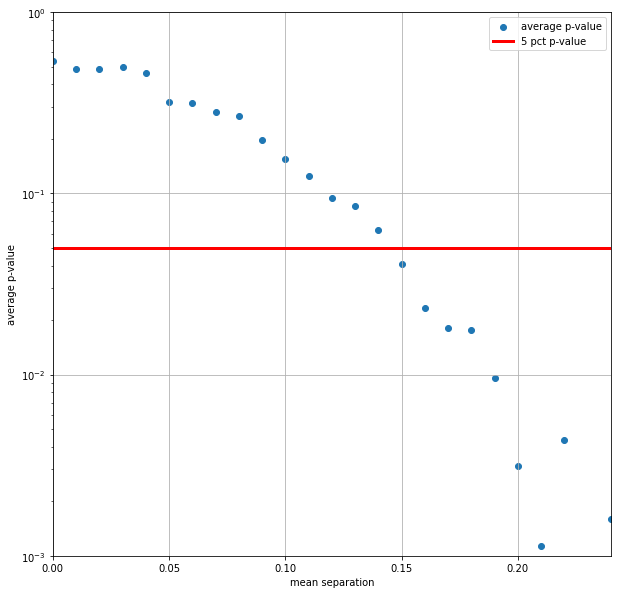

In [6]:
### make a plot ###

plt.figure(figsize=(10,10))
plt.subplot(1,1,1)

plt.scatter(mu2,ksp,label="average p-value")
plt.xlabel("mean separation")
plt.ylabel("average p-value")
plt.yscale("log")
plt.plot([mu2[0],mu2[len(mu2)-1]],[0.05,0.05],color='r',linewidth=3,label="5 pct p-value")
plt.axis([0.0,mu2[len(mu2)-1],0.001,1.0])
plt.grid()
plt.legend(loc="upper right")

plt.show()

From the graph above, we can see that we can expect to 

be able to separate the two distribtions at 95% c.l. 

if they have a mean separation of about 0.14. 